In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

In [2]:
N = 100
X = np.random.random(N) * 6 - 3
y = 0.5 * X - 1 + np.random.randn(N) * 0.5

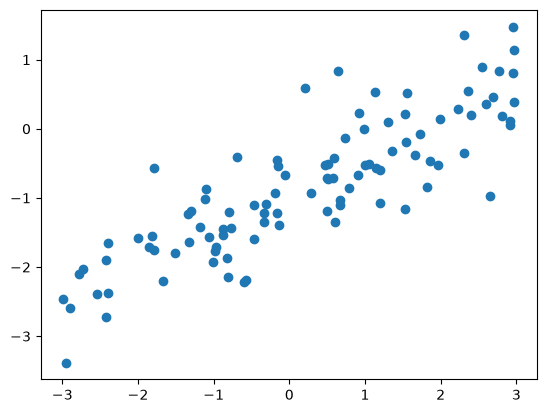

In [3]:
plt.scatter(X, y);

In [4]:
# build model
i = Input(shape=(1,))
x = Dense(1)(i)

model = Model(i, x)
# HOMEWORK

In [5]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 1)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    loss='mse',
    # optimizer='adam',
    optimizer=Adam(learning_rate=0.1),
    metrics=['mae']
)

In [7]:
r = model.fit(
    X.reshape(-1, 1), y,
    epochs=200,
    batch_size=32,
)

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 3.5217 - mae: 1.5493  
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.5669 - mae: 1.0200 
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5897 - mae: 0.6280 
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3336 - mae: 0.4516 
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4106 - mae: 0.5145 
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5009 - mae: 0.5706
Epoch 7/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4792 - mae: 0.5500
Epoch 8/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3847 - mae: 0.4833
Epoch 9/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3078 - mae: 0.4265
Epoch 10/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2740 - mae: 0.3919 
Epoch 11/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2887 - mae: 0.4076
Epoch 12/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3065 - mae: 0.4283
Epoch 13/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/ste

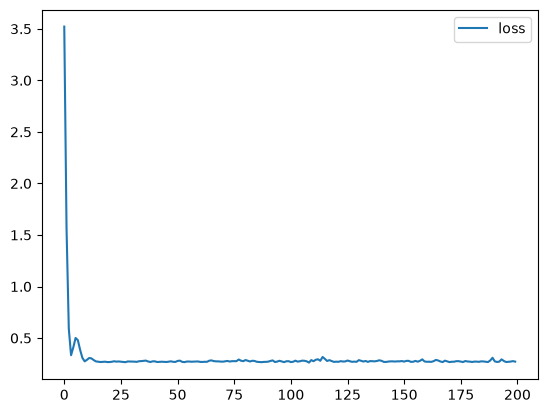

In [8]:
# Plot loss per iteration
plt.plot(r.history['loss'], label='loss')
plt.legend();

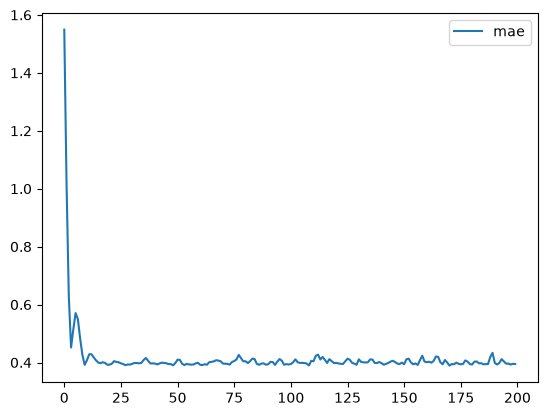

In [9]:
# Plot mae per iteration
plt.plot(r.history['mae'], label='mae')
plt.legend();

In [10]:
# Make predictions
Xtest = np.linspace(-3, 3, 20).reshape(-1, 1)
ptest = model.predict(Xtest)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


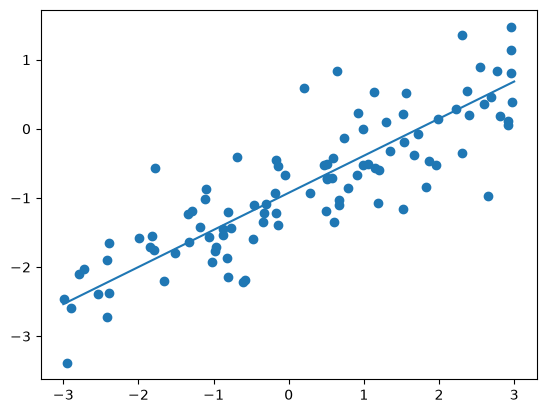

In [11]:
plt.scatter(X, y)
plt.plot(Xtest, ptest);

In [12]:
# Check the learned parameters
model.layers

[<InputLayer name=input_layer, built=True>, <Dense name=dense, built=True>]

In [13]:
model.layers[1].get_weights()

[array([[0.5367335]], dtype=float32), array([-0.9261018], dtype=float32)]

![](https://deeplearningcourses.com/notebooks_v3_pxl?sc=rNqZPzHeg0A0iHxXRZdjOA&n=Linear+Regression+%28Warmup+%26+Syntax%29)